# 05 · Frozen speech encoders and fusion

## Does a frozen WavLM encoder with a logistic head lead the ladder?

This notebook scores wav2vec2, HuBERT and WavLM (frozen, mean-pooled per
layer), builds an equal-weight fusion of logreg and WavLM probabilities, and
applies the selection rule (H26–H30).

**Inherits:** classical and CNN predictions; acoustic features; speaker split.
**Data:** 1,080 development clips for scoring; embeddings cover all 1,440
clips (label-free forward pass).
**Runtime:** seconds with saved predictions; hours with `RUN_HEAVY = True`
(encoder download + embedding extraction + head fits + layer probe + F11;
needs audio, disk, and preferably a GPU).
**Writes:** encoder and fusion preds, `selection.json`, layer probes, F09 /
F11 / F11b / F13.


In [1]:
# Setup: shared helpers, paths, and the switch for heavy steps.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
)

HERE = Path.cwd()
SHARED = next(p / "shared" for p in [HERE, *HERE.parents]
              if (p / "shared" / "audio_utils.py").exists())
sys.path.insert(0, str(SHARED))

import audio_utils as U
import cv_harness as H
import speaker_split as S

RUN_HEAVY = False  # True rebuilds from audio / features (minutes to hours)

SUB = U.submission_root()
OUT = SUB / "Modelling" / "outputs"
TABLES, FIGS, PREDS = OUT / "tables", OUT / "figures", OUT / "preds"
for d in (TABLES, FIGS, PREDS):
    d.mkdir(parents=True, exist_ok=True)
H.configure_paths(preds_dir=PREDS, tuning_log=TABLES / "tuning_log.csv")

EMOS = list(U.EMOTION_ORDER)
PCOLS = [f"p_{e}" for e in EMOS]
SUMMARY = []


def record(h, claim, verdict, evidence, decision):
    """Store one hypothesis result and print its verdict."""
    SUMMARY.append({
        "H": h, "hypothesis": claim, "verdict": verdict,
        "evidence": evidence, "so we": decision,
    })
    print(f"\n{h} · {claim}\n    verdict: {verdict.upper()}")


print(f"RUN_HEAVY={RUN_HEAVY}  preds={PREDS.relative_to(SUB)}")


RUN_HEAVY=False  preds=Modelling/outputs/preds


In [2]:
# Shared scoring helpers used by the live-compute path.
import re

TIERS = [
    (r"^logreg$", "M1", 1), (r"^svc$", "M1", 2), (r"^rf$", "M1", 3),
    (r"^gbm$", "M1", 4),
    (r"^logreg-(noweight|oversample|g\d)$", "M1a", 9),
    (r"-spkz$", "E4", 9),
    (r"^(wav2vec2|hubert|wavlm)$", "M3", 5),
    (r"^cnn$", "M2", 6), (r"^fusion", "M4", 7),
]
CANDIDATE_TIERS = {"M1", "M2", "M3", "M4"}


def tier_of(model: str):
    """Return (tier, simplicity_rank) for a model name."""
    for pat, tier, rank in TIERS:
        if re.search(pat, model):
            return tier, rank
    return "other", 99


def fold_metrics(df: pd.DataFrame) -> dict:
    """Accuracy, macro-F1, balanced accuracy and top-2 from one fold CSV."""
    yt, yp = df["true_emotion"].values, df["pred_emotion"].values
    out = {
        "accuracy": accuracy_score(yt, yp),
        "macro_f1": f1_score(
            yt, yp, average="macro", labels=EMOS, zero_division=0),
        "balanced_acc": balanced_accuracy_score(yt, yp),
        "top2_acc": float("nan"),
    }
    if all(c in df.columns for c in PCOLS):
        P = df[PCOLS].values
        top2 = np.argsort(-P, axis=1)[:, :2]
        truth = np.array([EMOS.index(e) for e in yt])
        out["top2_acc"] = float(
            np.mean([truth[i] in top2[i] for i in range(len(yt))]))
    return out


def fold_scores(model: str, split: str = "grouped") -> list[float]:
    """Macro-F1 of each fold for one model and split type."""
    return [
        fold_metrics(pd.read_csv(
            PREDS / f"{model}_{split}_fold{k}.csv"))["macro_f1"]
        for k in range(6)
    ]


def assert_close_frame(a: pd.DataFrame, b: pd.DataFrame, name: str,
                       atol: float = 1e-4):
    """Assert two numeric frames match within atol after rounding."""
    assert list(a.columns) == list(b.columns), f"{name} columns differ"
    assert len(a) == len(b), f"{name} row count differs"
    for c in a.columns:
        if pd.api.types.is_numeric_dtype(a[c]):
            aa, bb = a[c].astype(float).values, b[c].astype(float).values
            if not np.allclose(aa, bb, equal_nan=True, atol=atol):
                raise AssertionError(
                    f"{name}.{c} drifted: max "
                    f"{np.nanmax(np.abs(aa - bb)):.6g}")
        else:
            if not (a[c].astype(str).values == b[c].astype(str).values).all():
                raise AssertionError(f"{name}.{c} string values differ")
    print(f"[ok] live {name} matches saved file")


In [3]:
# Live: rebuild fusion as equal-weight average of logreg + wavlm probs.
members_path = TABLES / "fusion_members.txt"
members = members_path.read_text().strip()
print("fusion members:", members)
assert "logreg" in members and "wavlm" in members

for split in ("grouped", "random"):
    for fold in range(6):
        a = pd.read_csv(PREDS / f"logreg_{split}_fold{fold}.csv")
        b = pd.read_csv(PREDS / f"wavlm_{split}_fold{fold}.csv")
        assert (a["filepath"].values == b["filepath"].values).all()
        S.assert_no_test_speakers(a["filepath"], "fusion live")
        P = (a[PCOLS].values + b[PCOLS].values) / 2.0
        live = a[["filepath", "true_emotion"]].copy()
        live[PCOLS] = P
        live["pred_emotion"] = np.array(EMOS)[P.argmax(axis=1)]
        live["pred_confidence"] = P.max(axis=1)
        ref = pd.read_csv(PREDS / f"fusion_{split}_fold{fold}.csv")
        assert np.allclose(live[PCOLS].values, ref[PCOLS].values, atol=1e-5)
        assert (
            live["pred_emotion"].values == ref["pred_emotion"].values
        ).all()
print("[ok] fusion equals equal-weight average of logreg + wavlm")

# Live: encoder (+ fusion + classical needed) ladder rows from fold preds.
MODELS = [
    "logreg", "svc", "rf", "gbm", "cnn",
    "wav2vec2", "hubert", "wavlm", "fusion",
    "logreg-spkz", "wavlm-spkz",
]


def build_comparison(models):
    ref = {
        k: fold_metrics(pd.read_csv(
            PREDS / f"logreg_grouped_fold{k}.csv"))["macro_f1"]
        for k in range(6)
    }
    rows = []
    for model in models:
        tier, rank = tier_of(model)
        gr = [fold_metrics(pd.read_csv(
            PREDS / f"{model}_grouped_fold{k}.csv")) for k in range(6)]
        ra_path = PREDS / f"{model}_random_fold0.csv"
        ra = ([fold_metrics(pd.read_csv(
            PREDS / f"{model}_random_fold{k}.csv")) for k in range(6)]
              if ra_path.exists() else [])
        row = {
            "model": model, "tier": tier, "simplicity_rank": rank,
            "n_folds": 6,
        }
        for mname in ("macro_f1", "accuracy", "balanced_acc", "top2_acc"):
            gv = [g[mname] for g in gr]
            row[f"grouped_{mname}_mean"] = round(float(np.mean(gv)), 4)
            row[f"grouped_{mname}_sd"] = round(float(np.std(gv, ddof=1)), 4)
        if ra:
            rv = [r["macro_f1"] for r in ra]
            row["random_macro_f1_mean"] = round(float(np.mean(rv)), 4)
            row["leakage_gap"] = round(
                row["random_macro_f1_mean"] - row["grouped_macro_f1_mean"], 4)
        else:
            row["random_macro_f1_mean"] = np.nan
            row["leakage_gap"] = np.nan
        if model != "logreg":
            d = np.array([gr[k]["macro_f1"] - ref[k] for k in range(6)])
            row["wins_vs_logreg"] = f"{int((d > 0).sum())}/6"
            row["mean_diff_vs_logreg"] = round(float(d.mean()), 4)
        else:
            row["wins_vs_logreg"] = np.nan
            row["mean_diff_vs_logreg"] = np.nan
        rows.append(row)
    return pd.DataFrame(rows)


live_cmp = build_comparison(MODELS)
saved_cmp = pd.read_csv(TABLES / "model_comparison.csv")
# Compare on shared models / key columns.
common = [m for m in MODELS if m in set(saved_cmp["model"])]
L = live_cmp.set_index("model").loc[common]
S_ = saved_cmp.set_index("model").loc[common]
for col in ["grouped_macro_f1_mean", "grouped_macro_f1_sd", "leakage_gap"]:
    assert np.allclose(
        L[col].astype(float), S_[col].astype(float), equal_nan=True,
        atol=1e-4), col
print("[ok] model_comparison.csv matches live fold metrics")
cmp = saved_cmp
elig = cmp[cmp["tier"].isin(CANDIDATE_TIERS) & (cmp["n_folds"] == 6)].copy()


fusion members: logreg + wavlm, equal-weight probability average
[ok] fusion equals equal-weight average of logreg + wavlm


[ok] model_comparison.csv matches live fold metrics


In [4]:
# Live: selection rule in code; assert equal to selection.json.
cand = elig.sort_values(
    "grouped_macro_f1_mean", ascending=False).reset_index(drop=True)
lead = cand.iloc[0]
band = float(lead["grouped_macro_f1_mean"] - lead["grouped_macro_f1_sd"])
tied = cand[cand["grouped_macro_f1_mean"] >= band].sort_values(
    ["simplicity_rank", "grouped_macro_f1_mean"], ascending=[True, False])
chosen = tied.iloc[0]
live_sel = {
    "rule": ("highest mean speaker-grouped macro-F1 (6-fold dev CV); "
             "candidates within 1 sd of the leader are tied; a tie goes "
             "to the lowest simplicity rank"),
    "leader": lead["model"],
    "leader_macro_f1": float(lead["grouped_macro_f1_mean"]),
    "leader_sd": float(lead["grouped_macro_f1_sd"]),
    "tie_band_lower": round(band, 4),
    "tied": tied["model"].tolist(),
    "selected": chosen["model"],
    "selected_macro_f1": float(chosen["grouped_macro_f1_mean"]),
    "selected_sd": float(chosen["grouped_macro_f1_sd"]),
}
saved_sel = json.loads((TABLES / "selection.json").read_text())
assert live_sel["selected"] == saved_sel["selected"]
assert abs(
    live_sel["selected_macro_f1"] - saved_sel["selected_macro_f1"]
) < 1e-4
assert live_sel["tied"] == saved_sel["tied"]
print("[ok] selection.json matches live rule:", live_sel["selected"],
      live_sel["selected_macro_f1"])
m = elig.set_index("model")


[ok] selection.json matches live rule: wavlm 0.7535


### H26 · A frozen WavLM encoder with a logistic head beats classical logreg and the CNN on speaker-grouped CV

**Why it matters:** the pre-trained encoder is the most complex dependency on the ladder; it has to clear both earlier rungs to justify its place.

In [5]:
# H26
wavlm = float(m.loc["wavlm", "grouped_macro_f1_mean"])
logreg = float(m.loc["logreg", "grouped_macro_f1_mean"])
cnn = float(m.loc["cnn", "grouped_macro_f1_mean"])
print(f"wavlm={wavlm:.4f} logreg={logreg:.4f} cnn={cnn:.4f}")
verdict = (
    "supported" if wavlm > logreg and wavlm > cnn else "not supported")
record(
    "H26",
    "A frozen WavLM encoder with a logistic head beats classical logreg "
    "and the CNN on speaker-grouped CV",
    verdict,
    f"wavlm {wavlm:.4f}; logreg {logreg:.4f}; cnn {cnn:.4f}",
    "promote WavLM as the leading eligible model",
)


wavlm=0.7535 logreg=0.5169 cnn=0.4327

H26 · A frozen WavLM encoder with a logistic head beats classical logreg and the CNN on speaker-grouped CV
    verdict: SUPPORTED


**Verdict: supported. [EVIDENCE]** WavLM reaches 0.7535, against 0.5169 for logistic regression and 0.4327 for the CNN. A frozen encoder pre-trained on unlabelled speech, with only a logistic head trained here, adds more than any change of classifier on the hand-built features.

**So we** promote WavLM to the leading eligible model.

### H27 · Among frozen encoders, WavLM leads wav2vec2 and HuBERT on speaker-grouped CV

**Why it matters:** the headline model uses one encoder; choosing it on the same speaker-grouped CV keeps the choice comparable with every other rung.

In [6]:
# H27
ssl = {k: float(m.loc[k, "grouped_macro_f1_mean"])
       for k in ("wavlm", "wav2vec2", "hubert")}
print(ssl)
verdict = (
    "supported" if ssl["wavlm"] == max(ssl.values()) else "not supported")
record(
    "H27",
    "Among frozen encoders, WavLM leads wav2vec2 and HuBERT on "
    "speaker-grouped CV",
    verdict,
    ", ".join(f"{k}={v:.4f}" for k, v in ssl.items()),
    "use WavLM as the encoder in the headline model",
)


{'wavlm': 0.7535, 'wav2vec2': 0.7115, 'hubert': 0.6999}

H27 · Among frozen encoders, WavLM leads wav2vec2 and HuBERT on speaker-grouped CV
    verdict: SUPPORTED


**Verdict: supported. [EVIDENCE]** WavLM (0.7535) leads wav2vec2 (0.7115) and HuBERT (0.6999). All three clear the classical rung by a wide margin, so most of the gain comes from pre-training itself; WavLM adds the most.

**So we** use WavLM as the encoder of the headline model.

### H28 · Late fusion of classical logreg probabilities with WavLM beats WavLM alone

**Why it matters:** fusion doubles the models to run and explain; it is only worth that if it scores higher.

In [7]:
# H28
fusion = float(m.loc["fusion", "grouped_macro_f1_mean"])
print(f"fusion={fusion:.4f} wavlm={wavlm:.4f}")
verdict = "supported" if fusion > wavlm else "not supported"
record(
    "H28",
    "Late fusion of classical logreg probabilities with WavLM beats "
    "WavLM alone",
    verdict,
    f"fusion {fusion:.4f} vs wavlm {wavlm:.4f}",
    "do not prefer fusion over WavLM on grouped CV",
)


fusion=0.7233 wavlm=0.7535

H28 · Late fusion of classical logreg probabilities with WavLM beats WavLM alone
    verdict: NOT SUPPORTED


**Verdict: not supported. [EVIDENCE]** Fusion scores 0.7233, below WavLM alone at 0.7535. Averaging in the weaker classical probabilities pulls the encoder down: the hand-built features add nothing the encoder is missing.

**So we** drop fusion; a second model is not worth its complexity.

### H29 · The selection rule (highest grouped macro-F1; ties within 1 sd go to the simplest model) picks WavLM

**Why it matters:** the held-out exam scores exactly this choice, once, so the rule has to be applied in code and match the saved selection.

In [8]:
# H29
print("selected:", live_sel["selected"], live_sel["selected_macro_f1"],
      "tied:", live_sel["tied"])
print("tie band lower edge:", live_sel["tie_band_lower"])
verdict = (
    "supported" if live_sel["selected"] == "wavlm" else "not supported")
record(
    "H29",
    "The selection rule picks WavLM among eligible models",
    verdict,
    f"selected={live_sel['selected']}; tied={live_sel['tied']}",
    "freeze WavLM as the model for the one-shot held-out exam",
)


selected: wavlm 0.7535 tied: ['wavlm', 'wav2vec2', 'fusion']
tie band lower edge: 0.7065

H29 · The selection rule picks WavLM among eligible models
    verdict: SUPPORTED


**Verdict: supported. [EVIDENCE]** The rule names WavLM at 0.7535. wav2vec2 and fusion fall inside the tie band (lower edge 0.7065), so the tie goes to the simplest model; WavLM and wav2vec2 are equally simple, and WavLM scores higher.

**So we** freeze WavLM, and write its recipe into `model_choice.md` before any held-out clip is scored.

### H30 · Per-speaker z-scoring of WavLM embeddings lifts grouped macro-F1 further

**Why it matters:** a gain here needs per-caller calibration audio **[CONDITIONAL]**.

In [9]:
# H30
z = float(cmp.set_index("model").loc["wavlm-spkz", "grouped_macro_f1_mean"])
print(f"wavlm={wavlm:.4f} wavlm-spkz={z:.4f}")
verdict = "supported" if z > wavlm else "not supported"
record(
    "H30",
    "Per-speaker z-scoring of WavLM embeddings lifts grouped macro-F1 "
    "further",
    verdict,
    f"wavlm-spkz {z:.4f} vs wavlm {wavlm:.4f}",
    "keep -spkz as a conditional diagnostic, not the headline",
)


wavlm=0.7535 wavlm-spkz=0.8275

H30 · Per-speaker z-scoring of WavLM embeddings lifts grouped macro-F1 further
    verdict: SUPPORTED


**Verdict: supported. [CONDITIONAL]** Z-scoring each speaker's embeddings lifts WavLM from 0.7535 to 0.8275, the largest step on the ladder. Like the classical speaker-z variant, it needs calibration audio from each caller before it can score them.

**So we** report it as a conditional upper bound, not the headline.

### Encoder extraction, layer probe, heads and F11 (RUN_HEAVY)

Visible modelling code. With `RUN_HEAVY = False` the saved embeddings and predictions are used; the definitions stay in the notebook.

In [10]:
# Checkpoints and embedding extraction (visible always).
CHECKPOINTS = {
    "wav2vec2": (
        "facebook/wav2vec2-base",
        "0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8", "apache-2.0"),
    "hubert": (
        "facebook/hubert-base-ls960",
        "dba3bb02fda4248b6e082697eee756de8fe8aa8a", "apache-2.0"),
    "wavlm": (
        "microsoft/wavlm-base-plus",
        "4c66d4806a428f2e922ccfa1a962776e232d487b",
        "CC BY-SA 3.0"),
}
EMB_DIR = SUB / "cache" / "ssl_embeddings"
EMB_DIR.mkdir(parents=True, exist_ok=True)


def speech_signal(rel: str) -> np.ndarray:
    """Trim 30 dB and centre-crop/pad to the G2 window."""
    x = U.trimmed_signal(U.project_root() / rel)
    n = U.CLIP_SAMPLES
    return U.fix_length(x, n) if len(x) > n else x


def extract_encoder(name: str, device: str) -> Path:
    """Mean-pool hidden states per layer -> (1440, 13, 768) float32."""
    import time
    import torch
    from transformers import AutoFeatureExtractor, AutoModel

    repo, rev, lic = CHECKPOINTS[name]
    fe = AutoFeatureExtractor.from_pretrained(repo, revision=rev)
    model = AutoModel.from_pretrained(repo, revision=rev).to(device).eval()
    index = U.load_index()
    out = None
    t0 = time.time()
    with torch.no_grad():
        for i, rel in enumerate(index["filepath"]):
            x = speech_signal(rel)
            inp = fe(x, sampling_rate=U.TARGET_RATE, return_tensors="pt")
            h = model(
                inp["input_values"].to(device),
                output_hidden_states=True,
            ).hidden_states
            v = torch.stack(
                [layer[0].mean(dim=0) for layer in h]
            ).float().cpu().numpy()
            if out is None:
                out = np.zeros((len(index), *v.shape), dtype=np.float32)
            out[i] = v
            if (i + 1) % 240 == 0:
                print(f"  {name}: {i + 1}/{len(index)}", flush=True)
    path = EMB_DIR / f"emb_{name}.npy"
    np.save(path, out)
    meta = {
        "checkpoint": repo, "revision": rev, "licence": lic,
        "fine_tuned_for_emotion": False, "shape": list(out.shape),
        "pooling": ("mean over time, per hidden layer "
                    "(index 0 = CNN feature projection)"),
        "dtype": "float32",
    }
    (EMB_DIR / f"emb_{name}.json").write_text(json.dumps(meta, indent=2))
    (EMB_DIR / f"emb_{name}_manifest.json").write_text(json.dumps({
        "tag": name, "checkpoint": repo, "file": f"emb_{name}.npy",
        "shape": list(out.shape), "dtype": "float32",
        "pooling": meta["pooling"], "sr": 16000, "n_clips": 1440,
        "emotion_finetuned": False,
    }, indent=2))
    print(f"wrote {path.name} {out.shape} in {time.time() - t0:.0f}s")
    del model
    return path


from sklearn.base import BaseEstimator


class LayerLogreg(BaseEstimator):
    """Pick one hidden layer then fit logistic regression (inner-CV HPs)."""

    def __init__(self, layer=0, dim=768, C=0.1):
        self.layer, self.dim, self.C = layer, dim, C

    def fit(self, X, y, sample_weight=None):
        from sklearn.linear_model import LogisticRegression
        sl = X[:, self.layer * self.dim:(self.layer + 1) * self.dim]
        self.lr_ = LogisticRegression(
            C=self.C, max_iter=3000, class_weight="balanced",
            random_state=42)
        self.lr_.fit(sl, y)
        self.classes_ = self.lr_.classes_
        return self

    def predict_proba(self, X):
        sl = X[:, self.layer * self.dim:(self.layer + 1) * self.dim]
        return self.lr_.predict_proba(sl)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

    def get_params(self, deep=True):
        return {"layer": self.layer, "dim": self.dim, "C": self.C}

    def set_params(self, **kw):
        for k, v in kw.items():
            setattr(self, k, v)
        return self


print("encoder helpers ready; checkpoints:", list(CHECKPOINTS))


encoder helpers ready; checkpoints: ['wav2vec2', 'hubert', 'wavlm']


In [11]:
# RUN_HEAVY: extract embeddings, F11b layer profile, fit heads,
# fusion, F11. Layer profile is F11b only (C=0.1 via H.run_cv).
if RUN_HEAVY:
    import torch
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.metrics import f1_score as f1s

    device = "mps" if torch.backends.mps.is_available() else (
        "cuda" if torch.cuda.is_available() else "cpu")
    print("device:", device)
    for name in CHECKPOINTS:
        dest = EMB_DIR / f"emb_{name}.npy"
        if dest.exists():
            print(f"[cache hit] {dest.relative_to(SUB)}")
        else:
            extract_encoder(name, device)

    index = U.load_index()
    msk = S.dev_mask(index)
    y = index.loc[msk, "emotion"].to_numpy()
    g = index.loc[msk, "speaker"].astype(np.int64).to_numpy()
    fps = index.loc[msk, "filepath"].to_numpy()
    S.assert_no_test_speakers(fps, "SSL heavy")

    # F11b_layer_profile.csv + png (C=0.1, H.run_cv, mean and sd)
    f11b_rows = []
    for name in CHECKPOINTS:
        E = np.load(EMB_DIR / f"emb_{name}.npy")[msk]
        for layer in range(E.shape[1]):
            sc = H.run_cv(
                f"layer-{name}-{layer}",
                LogisticRegression(
                    C=0.1, max_iter=3000, class_weight="balanced",
                    random_state=42),
                E[:, layer].astype(np.float64), y, g, fps, "grouped",
                write=False, verbose=False,
                note="F11b layer profile C=0.1",
            )
            f11b_rows.append({
                "encoder": name, "layer": layer,
                "macro_f1_mean": round(float(np.mean(sc)), 4),
                "macro_f1_sd": round(float(np.std(sc, ddof=1)), 4),
            })
            print(name, layer, f11b_rows[-1]["macro_f1_mean"], flush=True)
    f11b = pd.DataFrame(f11b_rows)
    f11b.to_csv(TABLES / "F11b_layer_profile.csv", index=False)
    fig, ax = plt.subplots(figsize=(8, 4))
    colors = ["#8E5FA8", "#4B7BB5", "#E8A33D"]
    for (name, sub), col in zip(f11b.groupby("encoder"), colors):
        ax.plot(sub.layer, sub.macro_f1_mean, "o-", color=col, label=name)
        ax.fill_between(
            sub.layer,
            sub.macro_f1_mean - sub.macro_f1_sd,
            sub.macro_f1_mean + sub.macro_f1_sd,
            color=col, alpha=0.12)
    ax.set_xticks(range(int(f11b.layer.max()) + 1))
    U.finish_axes(
        ax,
        "F11b - Where in the frozen encoder does emotion live?",
        "layer (0 = convolutional front end, 12 = last "
        "transformer layer)",
        "macro-F1 (speaker-grouped, +/-1 sd)",
        source=("Source: own analysis, logreg C=0.1 per layer, "
                "1,080 dev clips; "
                "Modelling/outputs/tables/F11b_layer_profile.csv"),
        legend=True)
    U.save_figure(fig, "F11b_layer_profile.png", out_dir=FIGS)
    plt.show()

    # Per-fold heads: layer + C by inner CV (plain and -spkz).
    for name in CHECKPOINTS:
        E = np.load(EMB_DIR / f"emb_{name}.npy")
        n_layers, dim = E.shape[1], E.shape[2]
        X = E[msk].reshape(
            int(msk.sum()), n_layers * dim).astype(np.float64)
        grid = {"layer": list(range(n_layers)), "C": [0.01, 0.1, 1.0]}
        for st in ("grouped", "random"):
            H.run_cv(
                name, LayerLogreg(dim=dim), X, y, g, fps, st,
                param_grid=grid,
                note=f"M3 frozen {name}, mean-pooled, layer + C by "
                     f"inner CV")
            H.run_cv(
                f"{name}-spkz", LayerLogreg(dim=dim), X, y, g, fps, st,
                param_grid=grid, speaker_norm=True,
                note=f"E4 {name}-spkz")

    # Fusion: equal-weight logreg + wavlm.
    for st in ("grouped", "random"):
        for k in range(6):
            a = pd.read_csv(PREDS / f"logreg_{st}_fold{k}.csv")
            b = pd.read_csv(PREDS / f"wavlm_{st}_fold{k}.csv")
            P = (a[PCOLS].values + b[PCOLS].values) / 2.0
            H.save_preds(
                PREDS / f"fusion_{st}_fold{k}.csv",
                a["filepath"].values, a["true_emotion"].values, P, EMOS)
    (TABLES / "fusion_members.txt").write_text(
        "logreg + wavlm, equal-weight probability average\n")

    # F11 permutation importance on tuned logreg (acoustic features).
    import features as F
    from sklearn.pipeline import make_pipeline

    Xf, yf, gf, fpsf, cols = H.load_feature_frame()
    Xf = np.nan_to_num(Xf)
    groups = {
        k: [j for j, c in enumerate(cols) if F.feature_group(c) == k]
        for k in F.FEATURE_GROUPS
    }
    rng = np.random.default_rng(42)
    tlog = pd.read_csv(TABLES / "tuning_log.csv")
    rows, feat_rows = [], []
    for k, (tr, va) in enumerate(H.outer_splits("grouped", Xf, yf, gf)):
        sub = tlog[(tlog.model == "logreg") & (tlog.split_type == "grouped")
                   & (tlog.fold == k)]
        C = (json.loads(sub.iloc[0]["best_params"])["C"]
             if len(sub) else 0.1)
        pipe = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=C, max_iter=3000, class_weight="balanced",
                random_state=42),
        ).fit(Xf[tr], yf[tr])
        base = f1_score(yf[va], pipe.predict(Xf[va]), average="macro")
        for grp, idx in groups.items():
            for r in range(5):
                Xp = Xf[va].copy()
                Xp[:, idx] = Xp[rng.permutation(len(va))][:, idx]
                rows.append({
                    "fold": k, "group": grp, "n_cols": len(idx),
                    "drop": base - f1_score(
                        yf[va], pipe.predict(Xp), average="macro"),
                })
        for j, cname in enumerate(cols):
            Xp = Xf[va].copy()
            Xp[:, j] = Xp[rng.permutation(len(va)), j]
            feat_rows.append({
                "fold": k, "feature": cname,
                "group": F.feature_group(cname),
                "drop": base - f1_score(
                    yf[va], pipe.predict(Xp), average="macro"),
            })
    sdf = pd.DataFrame(rows)
    s = (sdf.groupby(["group", "n_cols"])["drop"]
         .agg(["mean", "std"]).reset_index().sort_values("mean"))
    s.round(4).to_csv(TABLES / "F11_group_importance.csv", index=False)
    ft = (pd.DataFrame(feat_rows).groupby(["feature", "group"])["drop"]
          .mean().reset_index().sort_values("drop", ascending=False))
    ft.round(5).to_csv(TABLES / "F11_feature_importance.csv", index=False)
    print("[RUN_HEAVY] SSL + fusion + F11 tables rewritten")
else:
    print("[cache hit] encoder preds / fusion / F11b / F11 tables")


[cache hit] encoder preds / fusion / F11b / F11 tables


[cache hit] Modelling/outputs/figures/F09_model_comparison.png


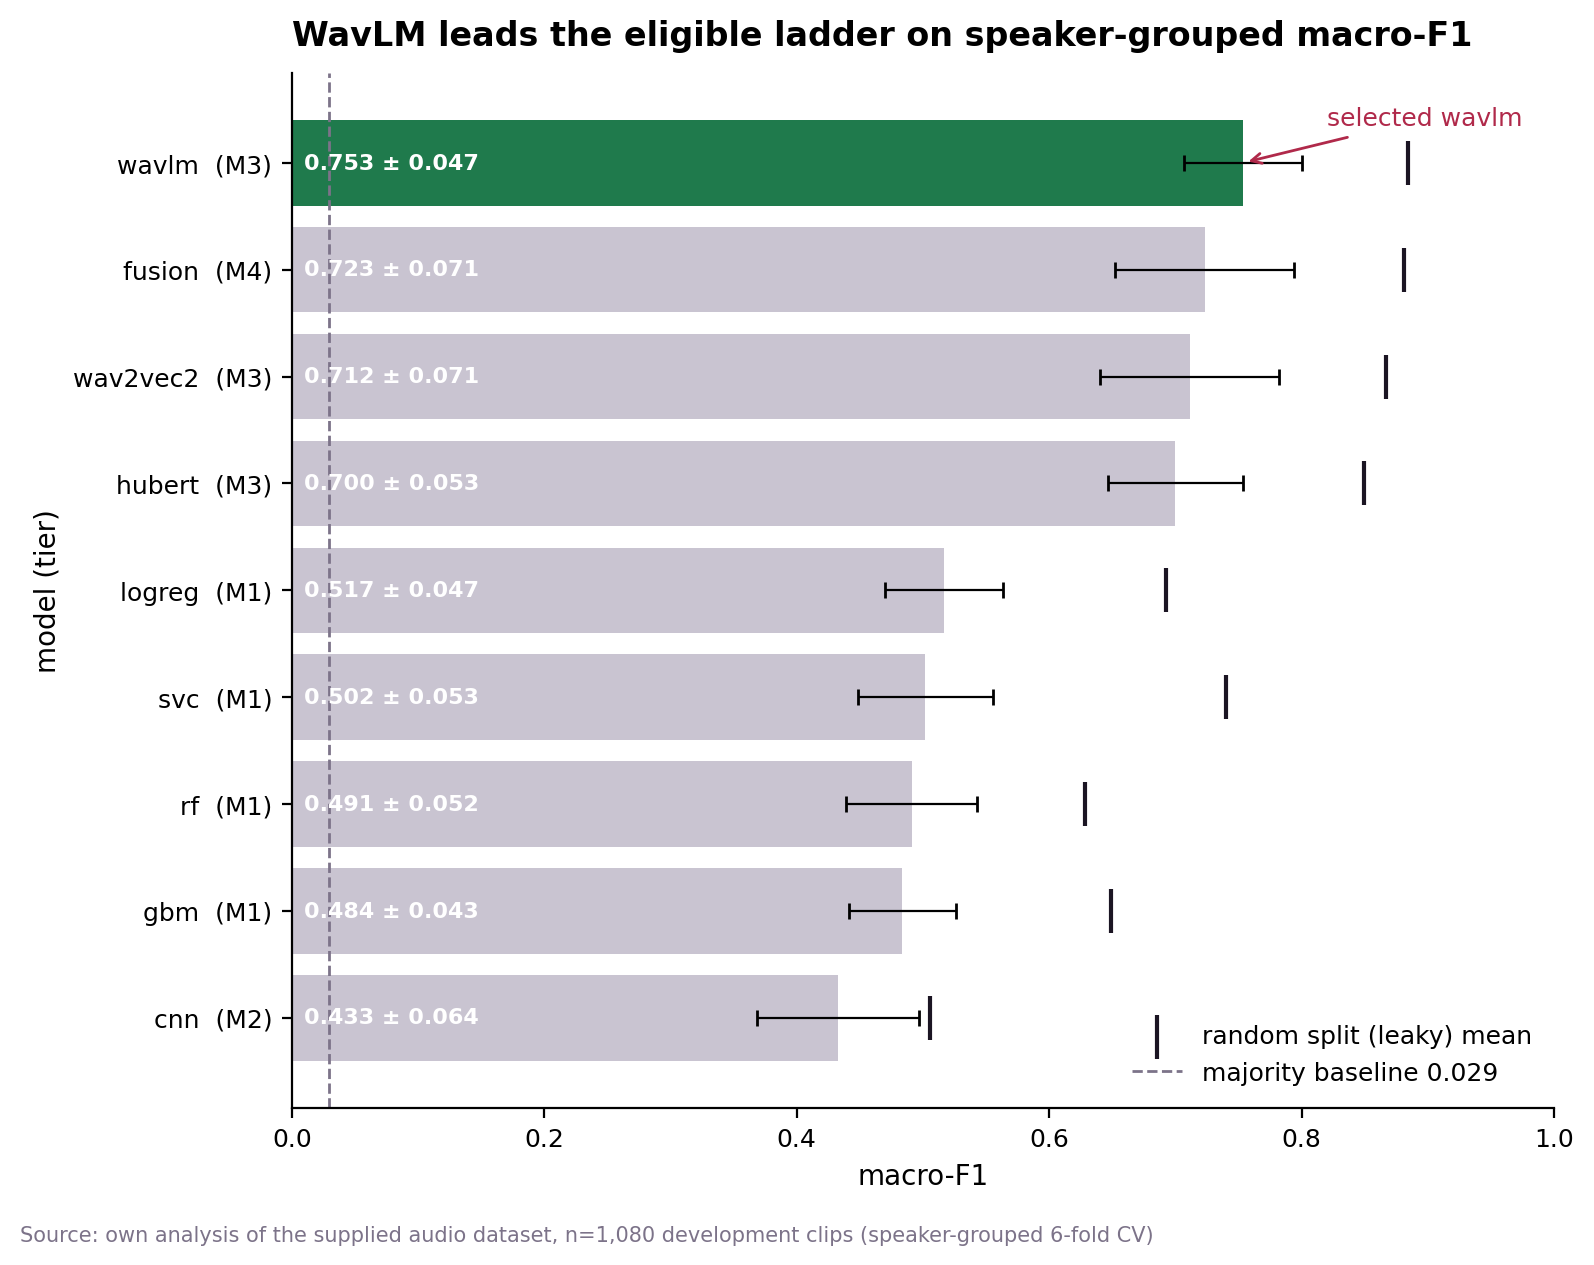

[cache hit] Modelling/outputs/figures/F11_feature_importance.png


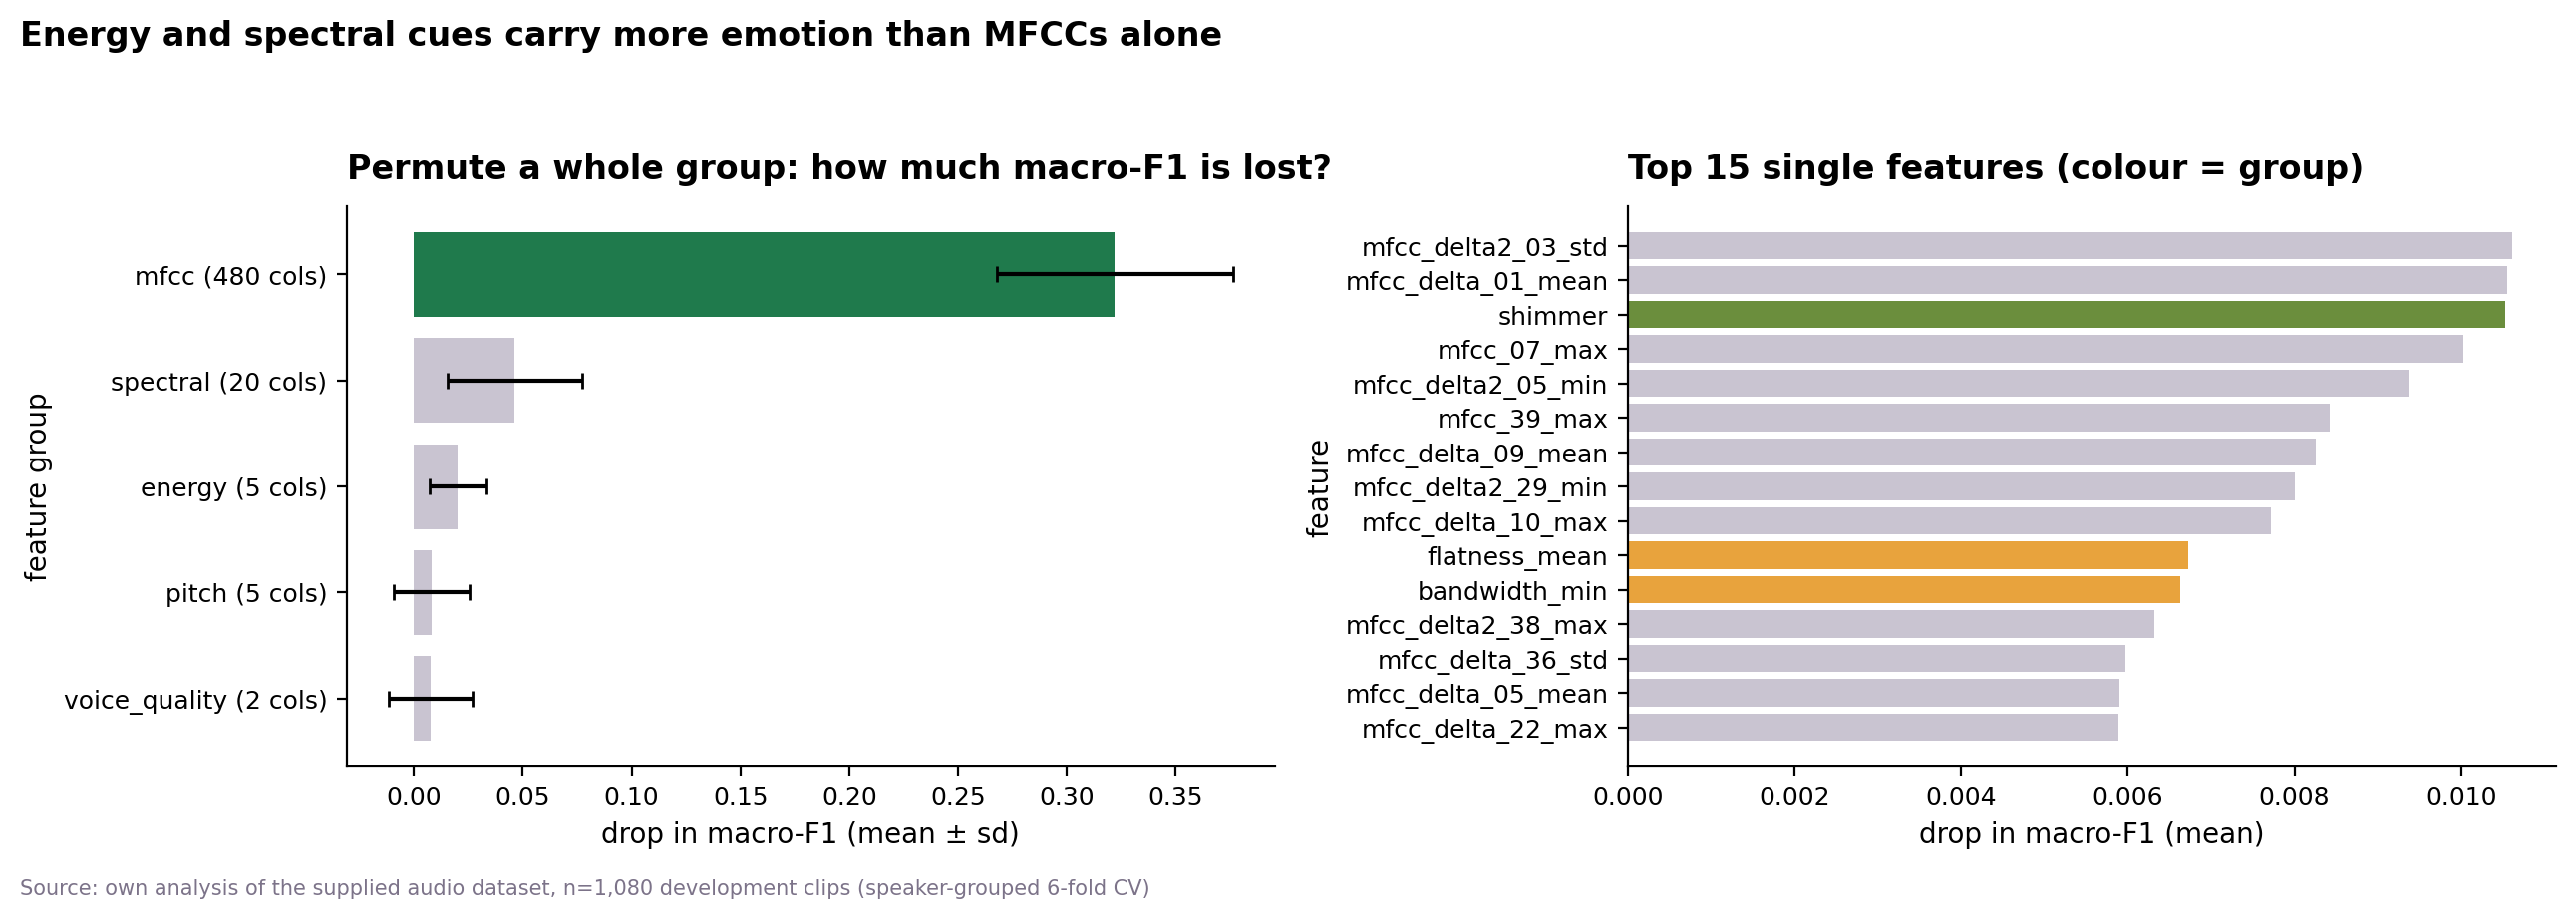

[cache hit] Modelling/outputs/figures/F13_split_gap.png


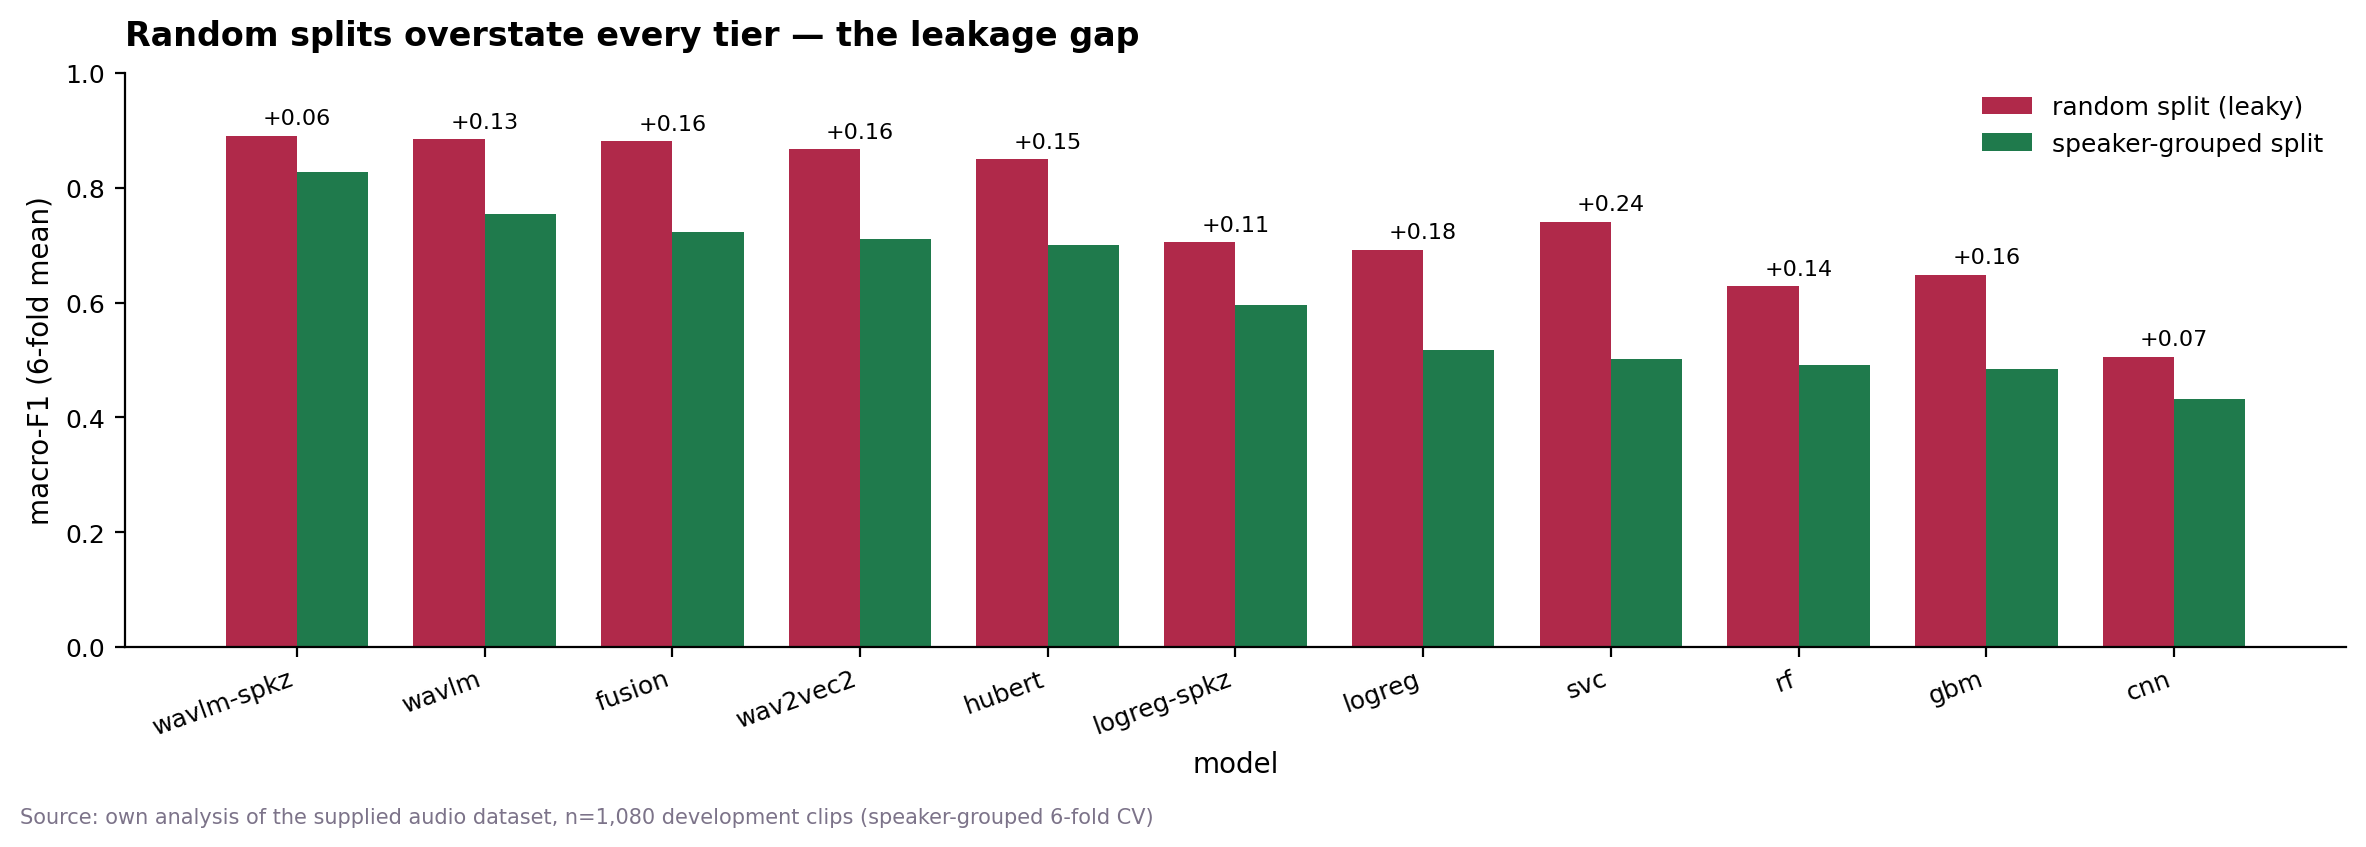

[cache hit] Modelling/outputs/tables/F11b_layer_profile.csv
[cache hit] Modelling/outputs/figures/F11b_layer_profile.png


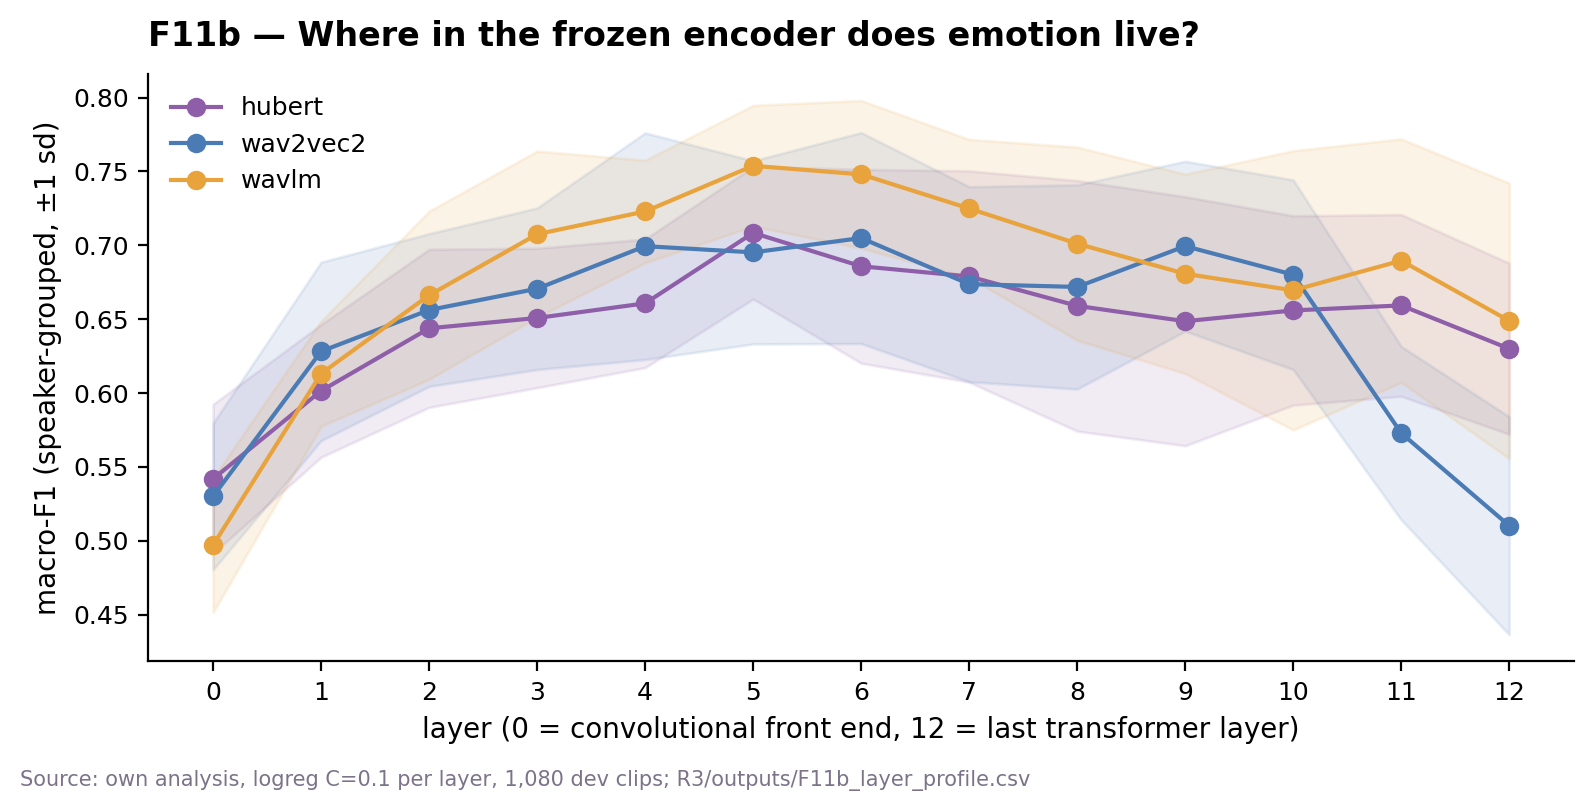

In [12]:
# Redraw F09, F11, F13 only when missing or RUN_HEAVY (protect shipped PNGs).
# On the cache-hit path, display the saved PNGs inline.
from IPython.display import Image, display
import redraw_modelling_figures as R

need = [
    FIGS / "F09_model_comparison.png",
    FIGS / "F11_feature_importance.png",
    FIGS / "F13_split_gap.png",
]
if RUN_HEAVY or not all(p.exists() for p in need):
    base = pd.read_csv(TABLES / "baselines_rows.csv")
    base_f1 = float(
        base.loc[base["model"] == "majority", "macro_f1"].iloc[0])
    R.plot_f09(cmp, base_f1)
    R.plot_f11()
    R.plot_f13(cmp)
    print("redrawn F09, F11, F13")
    for p in need:
        if p.exists():
            display(Image(filename=str(p)))
else:
    for p in need:
        print(f"[cache hit] {p.relative_to(SUB)}")
        display(Image(filename=str(p)))
prof = TABLES / "F11b_layer_profile.csv"
fig = FIGS / "F11b_layer_profile.png"
if prof.exists():
    print(f"[cache hit] {prof.relative_to(SUB)}")
if fig.exists():
    print(f"[cache hit] {fig.relative_to(SUB)}")
    display(Image(filename=str(fig)))


In [13]:
# Summary table for this notebook.
summary = pd.DataFrame(SUMMARY).set_index("H")
display(summary)
summary.to_csv(TABLES / "summary_05.csv")


,hypothesis,verdict,evidence,so we
H,,,,
H26,A frozen WavLM encoder with a logistic head be...,supported,wavlm 0.7535; logreg 0.5169; cnn 0.4327,promote WavLM as the leading eligible model
H27,"Among frozen encoders, WavLM leads wav2vec2 an...",supported,"wavlm=0.7535, wav2vec2=0.7115, hubert=0.6999",use WavLM as the encoder in the headline model
H28,Late fusion of classical logreg probabilities ...,not supported,fusion 0.7233 vs wavlm 0.7535,do not prefer fusion over WavLM on grouped CV
H29,The selection rule picks WavLM among eligible ...,supported,"selected=wavlm; tied=['wavlm', 'wav2vec2', 'fu...",freeze WavLM as the model for the one-shot hel...
H30,Per-speaker z-scoring of WavLM embeddings lift...,supported,wavlm-spkz 0.8275 vs wavlm 0.7535,"keep -spkz as a conditional diagnostic, not th..."


**Hands on:** WavLM selected; predictions and selection.json ready for Evaluation.